# Identification thermique par réseau convolutif 1D (CNN)

## Objectif de l'expérience

Cette expérience étudie la capacité d'un **réseau de neurones convolutif unidimensionnel** (*Convolutional Neural Network*, CNN 1D) à estimer les paramètres thermiques d'un bâtiment directement à partir de sa réponse temporelle.

Chaque simulation contient deux signaux de **480 observations** : la température $T$ et la sollicitation thermique $U$. Contrairement au MLP, le CNN exploite la succession temporelle des mesures plutôt que des caractéristiques statistiques préalablement extraites.

Le protocole comprend la préparation des séries temporelles, la définition du CNN, l'entraînement avec sélection sur validation et l'évaluation sur les ensembles de test.

## 1. Environnement d'exécution

Les fonctions de chargement des données, de définition des modèles, d'entraînement et d'évaluation sont regroupées dans src/coenergy/ afin de faciliter la réutilisation du code et la reproductibilité des expériences.

In [ ]:

from pathlib import Path
import sys
import shutil

import torch
from IPython.display import display


def find_source_directory():
    """Localise le dossier contenant les modules du projet."""

    # Recherche sur le PC
    current_directory = Path.cwd()

    for directory in [current_directory, *current_directory.parents]:
        source_directory = directory / "src"

        if (source_directory / "coenergy" / "loss.py").is_file():
            return source_directory

    # Recherche sur Kaggle
    kaggle_directory = Path("/kaggle/input")

    if kaggle_directory.exists():
        for file in kaggle_directory.rglob("loss.py"):
            if file.parent.name == "coenergy":
                return file.parent.parent

    raise FileNotFoundError("Modules coEnergy introuvables.")


source_directory = find_source_directory()
sys.path.insert(0, str(source_directory))

from coenergy.data import load_data, BatchStore
from coenergy.models import build_model
from coenergy.loss import reconstruct_six, family_loss
from coenergy.training import default_config, seed_everything, Experiment
from coenergy.evaluation import evaluate_all, extreme_diagnostics
from coenergy.plotting import plot_training, plot_scores, plot_scatter

print("Modules coEnergy chargés avec succès.")
print("Chemin :", source_directory)
print("GPU disponible :", torch.cuda.is_available())


Modules coEnergy chargés avec succès.
Modules : /kaggle/input/datasets/bilaoo/modules/src
GPU disponible : True


## 2. Configuration expérimentale

L'entraînement du CNN 1D repose sur **100 époques**, des mini-batchs de **1 024 simulations** et l'optimiseur **AdamW**, avec un taux d'apprentissage initial de **0,001**, ajusté selon la perte de validation.

Les hyperparamètres sont définis dans `training.py` et conservés identiques à ceux des modèles de référence afin d'assurer une comparaison cohérente.

Une graine aléatoire fixe (**2026**) et un identifiant d'expérience (`RUN_ID`) facilitent la reproductibilité et la traçabilité des entraînements.

In [ ]:
MODEL_KIND = "cnn"
RUN_ID = "run_001"
DATA_ROOT = (
    Path("/kaggle/input/datasets/bilalaouiss/dataset")
    if Path("/kaggle/input/datasets/bilalaouiss/dataset").is_dir()
    else None
)
RUN_TRAINING = True
RESUME = True

config = default_config(MODEL_KIND, RUN_ID)
seed_everything(config.seed)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if Path("/kaggle/working").is_dir():
    results_directory = Path("/kaggle/working/results")
else:
    results_directory = source_directory.parent / "results"

output_directory = results_directory / MODEL_KIND / RUN_ID

print("Modèle :", MODEL_KIND)
print("Appareil :", device)
print("Époques :", config.max_epochs)
print("Taille des mini-batchs :", config.batch_size)
print("Résultats :", output_directory)

Modèle : cnn
Appareil : cuda
Époques : 100
Taille des mini-batchs : 1024
Résultats : /kaggle/working/results/cnn/run_001


## 3. Données préparées et partitions

Le jeu de données comporte **1 000 000 de simulations**, réparties lors de l'analyse exploratoire. Les mêmes partitions sont utilisées pour toutes les architectures afin de permettre des comparaisons cohérentes.

| Partition | Simulations | Utilisation |
|---|---:|---|
| Entraînement | 719 885 | Ajustement des paramètres du réseau |
| Validation | 89 985 | Suivi de l'apprentissage et sélection du meilleur checkpoint |
| Test principal | 89 987 | Mesure des performances sur des simulations non utilisées à l'entraînement |
| Réserve U | 100 143 | Évaluation sur les profils de sollicitation mis de côté lors de l'EDA |


In [8]:
data = load_data(DATA_ROOT, expected_n=1_000_000)

for partition_name, indices in data.splits.items():
    print(f"{partition_name:12s} : {len(indices):,} simulations")

print("Séries temporelles :", data.sequences.shape)
print("Cibles thermiques :", data.targets.shape)

Données préparées : 1,000,000 simulations
Caractéristiques MLP : 58
train        : 719,885 simulations
validation   : 89,985 simulations
test         : 89,987 simulations
reserve_u    : 100,143 simulations
Séries temporelles : (1000000, 2, 480)
Cibles thermiques : (1000000, 6)


## 4. Préparation des séries temporelles

Chaque simulation est représentée par un tableau de dimension **$2\times480$** : un canal pour la température $T$ et un canal pour la sollicitation $U$. Cette organisation correspond au format attendu par une convolution 1D dans PyTorch : *(batch, canaux, temps)*.

Les signaux sont normalisés à partir de statistiques calculées **exclusivement sur l'entraînement** :

$$
\widetilde{T}=\frac{T-\mu_{T,\mathrm{train}}}{\sigma_{T,\mathrm{train}}},
\qquad
\widetilde{U}=\frac{U}{\mathrm{RMS}_{U,\mathrm{train}}}.
$$

La température est centrée et réduite ; la sollicitation est divisée par sa valeur quadratique moyenne, sans centrage. Ces transformations sont appliquées de manière identique aux quatre partitions.

La classe `BatchStore` prépare les données en mémoire et fournit ensuite les mini-batchs. Le CNN n'utilise **pas** les caractéristiques statistiques employées par le MLP.

In [9]:
training_data = BatchStore(
    bundle=data,
    mode="cnn",
    device=device,
)

sample_signals, sample_targets = training_data.get_batch(
    data.splits["train"][:8]
)

print("Entrées du CNN :", tuple(sample_signals.shape))
print("Cibles :", tuple(sample_targets.shape))

Données cnn en mémoire : cuda
Entrées du CNN : (8, 2, 480)
Cibles : (8, 6)


## 5. Architecture du réseau convolutif 1D

Le CNN applique trois convolutions temporelles successives aux deux signaux. Elles apprennent des motifs locaux susceptibles de caractériser l'évolution de la température en réponse à la sollicitation thermique.

| Couche | Canaux | Longueur temporelle |
|---|---:|---:|
| Entrée | 2 | 480 |
| Convolution 1D, noyau 7, pas 2 | 16 | 240 |
| Convolution 1D, noyau 5, pas 2 | 32 | 120 |
| Convolution 1D, noyau 5, pas 2 | 48 | 60 |

Chaque convolution est suivie d'une activation **SiLU**. Une moyenne et un maximum globaux sont ensuite calculés pour chaque canal, ce qui forme **96 valeurs**. Le réseau utilise des couches denses de dimensions $96\to64\to96\to5$, avec **dropout** pour la régularisation.

La sortie **Softplus**, associée aux moyennes des cibles d'entraînement, garantit cinq estimations positives :

$$
\left[\widehat{HLC}_{ext},\widehat{HLC}_{mit},
\widehat{\tau}_b,\widehat{\tau}_n,\widehat{\tau}_{\infty}\right].
$$

Le coefficient total de déperdition thermique est reconstruit à partir de la relation physique :

$$
\widehat{HLC}=\widehat{HLC}_{ext}+\widehat{HLC}_{mit}.
$$

L'architecture est définie dans `models.py`. Son nombre de paramètres entraînables est affiché ci-dessous.

In [10]:
model = build_model(MODEL_KIND, data.prep).to(device)

number_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

model.eval()

with torch.no_grad():
    five_predictions = model(sample_signals)
    six_predictions = reconstruct_six(five_predictions)

print(model)
print("Paramètres entraînables :", f"{number_parameters:,}")
print("Sorties indépendantes :", tuple(five_predictions.shape))
print("Indicateurs reconstruits :", tuple(six_predictions.shape))

CNN1DSeul(
  (cnn): Sequential(
    (0): Conv1d(2, 16, kernel_size=(7,), stride=(2,), padding=(3,))
    (1): SiLU()
    (2): Conv1d(16, 32, kernel_size=(5,), stride=(2,), padding=(2,))
    (3): SiLU()
    (4): Conv1d(32, 48, kernel_size=(5,), stride=(2,), padding=(2,))
    (5): SiLU()
  )
  (project): Sequential(
    (0): Linear(in_features=96, out_features=64, bias=True)
    (1): SiLU()
    (2): Dropout(p=0.1, inplace=False)
  )
  (head): Sequential(
    (0): Linear(in_features=64, out_features=96, bias=True)
    (1): SiLU()
    (2): Dropout(p=0.1, inplace=False)
    (3): Linear(in_features=96, out_features=5, bias=True)
  )
)
Paramètres entraînables : 23,493
Sorties indépendantes : (8, 5)
Indicateurs reconstruits : (8, 6)


## 6. Fonction de perte

L'apprentissage repose sur les **cinq indicateurs indépendants**. Les erreurs sont divisées par les écarts-types des cibles calculés sur l'entraînement, afin de rendre les paramètres de différentes échelles comparables.

Deux familles sont considérées : les deux composantes des déperditions thermiques ($HLC_{ext}$ et $HLC_{mit}$), et les trois constantes de temps ($\tau_b$, $\tau_n$, $\tau_\infty$).

$$
\mathcal{L}=0{,}50\,\mathcal{L}_{HLC}+0{,}50\,\mathcal{L}_{\tau},
$$

où chaque terme représente la **moyenne des erreurs quadratiques normalisées** des paramètres de sa famille.

Le HLC total est déduit de ses composantes et n'est donc pas comptabilisé une seconde fois dans la fonction de perte.

In [11]:
initial_loss = family_loss(
    five_predictions,
    sample_targets,
    data.prep["target_std"],
    hlc_weight=config.hlc_weight,
    tau_weight=config.tau_weight,
)

print("Perte initiale :", round(initial_loss.item(), 6))
print("Poids des déperditions :", config.hlc_weight)
print("Poids des constantes de temps :", config.tau_weight)

Perte initiale : 1.094411
Poids des déperditions : 0.5
Poids des constantes de temps : 0.5


## 7. Entraînement et sélection du modèle

Le CNN est entraîné sur l'ensemble d'apprentissage, tandis que la perte de validation est calculée à chaque époque pour suivre la généralisation et ajuster le taux d'apprentissage.

L'optimisation repose sur **AdamW**, avec une limitation des gradients et l'utilisation de la précision mixte sur GPU.

Le modèle présentant la **plus faible perte de validation** est conservé pour l'évaluation finale. Les checkpoints et l'historique d'entraînement sont également sauvegardés afin d'assurer la traçabilité des expériences.

In [12]:
experiment = Experiment(
    config=config,
    bundle=data,
    store=training_data,
    model=model,
    out_dir=output_directory,
    device=device,
)

if RUN_TRAINING:
    history = experiment.fit(resume=RESUME)
    print("Époques enregistrées :", len(history))
else:
    print("Entraînement désactivé : utilisation des checkpoints existants.")


Mini-batch 100 | Loss train : 0.94847
Mini-batch 200 | Loss train : 0.93671
Mini-batch 300 | Loss train : 0.92983
Mini-batch 400 | Loss train : 0.92592
Mini-batch 500 | Loss train : 0.92257
Mini-batch 600 | Loss train : 0.92055
Mini-batch 700 | Loss train : 0.91944
Époque 001 | train=0.91940 | validation=0.92019 | meilleure=1 | durée=5.4s
Mini-batch 100 | Loss train : 0.91335
Mini-batch 200 | Loss train : 0.91132
Mini-batch 300 | Loss train : 0.91213
Mini-batch 400 | Loss train : 0.91081
Mini-batch 500 | Loss train : 0.91051
Mini-batch 600 | Loss train : 0.91031
Mini-batch 700 | Loss train : 0.90938
Époque 002 | train=0.90937 | validation=0.91366 | meilleure=2 | durée=4.5s
Mini-batch 100 | Loss train : 0.90655
Mini-batch 200 | Loss train : 0.90504
Mini-batch 300 | Loss train : 0.90710
Mini-batch 400 | Loss train : 0.90810
Mini-batch 500 | Loss train : 0.90567
Mini-batch 600 | Loss train : 0.90560
Mini-batch 700 | Loss train : 0.90564
Époque 003 | train=0.90566 | validation=0.92654 | me

## 8. Évolution de l'apprentissage

Le meilleur checkpoint est déterminé uniquement à partir de la **perte de validation**. Les courbes d'entraînement et de validation permettent d'examiner la convergence du CNN ainsi qu'un éventuel surapprentissage.

Le graphique indique également les variations du taux d'apprentissage. L'évaluation finale utilise les poids enregistrés dans `best.pt`, et non ceux de la dernière époque.

Meilleure époque : 100


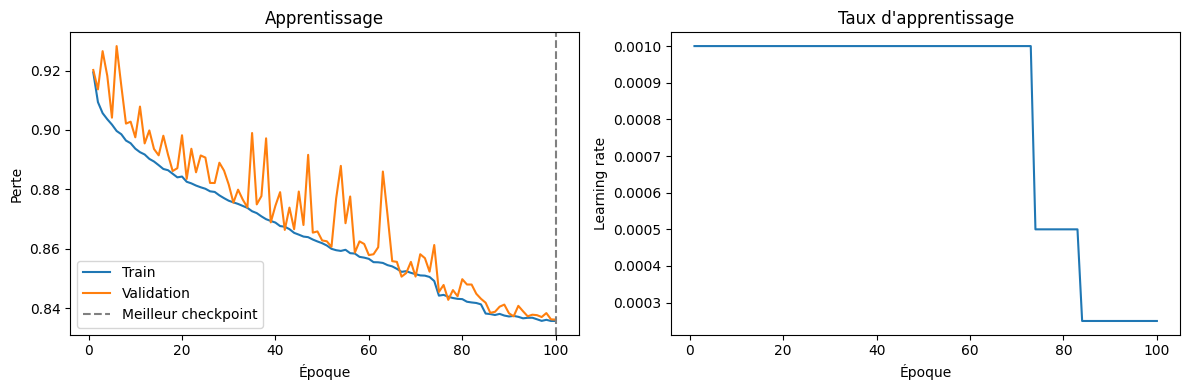

In [13]:
best_epoch = experiment.load_best()

print("Meilleure époque :", best_epoch)

plot_training(
    experiment.history_path,
    output_directory / "figures",
    best_epoch,
)


## 9. Évaluation des performances

Le CNN retenu est évalué sur la validation, le **test principal** et la **réserve U**. Les principales métriques sont calculées séparément pour chacun des six indicateurs thermiques :

- **MAE** : moyenne des erreurs absolues, dans l'unité du paramètre ;
- **RMSE** : racine de l'erreur quadratique moyenne, sensible aux erreurs importantes ;
- **$R^2$** : coefficient de détermination, évaluant la qualité des prédictions par rapport à une prédiction constante égale à la moyenne des valeurs réelles de la partition.

Une référence supplémentaire, qui prédit les **moyennes des cibles d'entraînement**, permet de situer les performances du CNN. Les ensembles de test servent à la comparaison finale et non au réglage des hyperparamètres.

,partition,target,unit,MAE,RMSE,R2,bias
12,test,HLC,W/K,19.8925,24.9783,0.3655,1.2359
13,test,HLCext,W/K,11.9982,14.9605,0.2334,0.4286
14,test,HLCmit,W/K,18.4344,22.8520,0.2437,0.8073
15,test,tau_b,h,7.7077,9.8157,0.0513,-0.2005
16,test,tau_n,h,1.4062,1.7912,0.2053,-0.0020
17,test,tau_inf,h,5.7238,7.3298,0.0475,-0.0937
24,reserve_u,HLC,W/K,19.6719,24.6900,0.3801,0.8599
25,reserve_u,HLCext,W/K,12.0725,15.0584,0.2229,0.2572
26,reserve_u,HLCmit,W/K,18.3129,22.7112,0.2532,0.6027
27,reserve_u,tau_b,h,7.7477,9.8872,0.0469,-0.1446


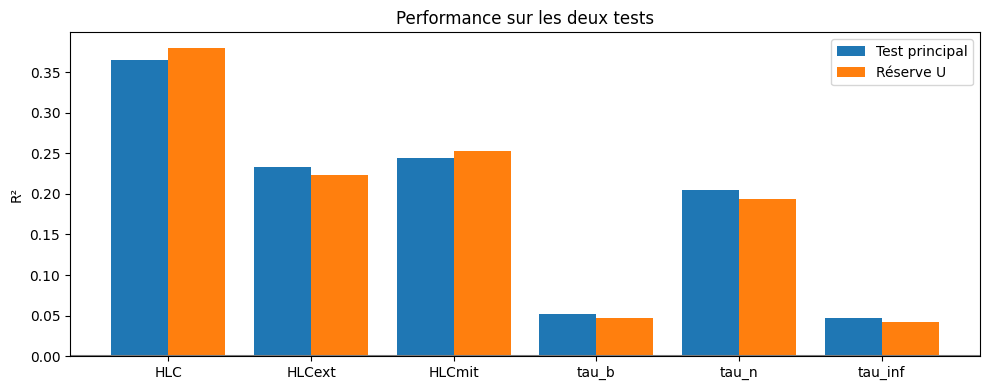

In [14]:
metrics = evaluate_all(experiment)

selected_metrics = metrics[
    (metrics["model"] == MODEL_KIND)
    & (metrics["partition"].isin(["test", "reserve_u"]))
]

display(
    selected_metrics[
        ["partition", "target", "unit", "MAE", "RMSE", "R2", "bias"]
    ].round(4)
)

plot_scores(metrics, MODEL_KIND, output_directory / "figures")


## 10. Analyse des prédictions et des valeurs extrêmes

Les diagrammes de dispersion mettent en regard les valeurs réelles et prédites des six indicateurs sur le test principal. La diagonale représente une prédiction parfaite ; un écart à cette ligne traduit une erreur d'estimation.

Une analyse complémentaire examine les constantes de temps $\tau_b$ et $\tau_\infty$ dans les régions extrêmes de leur distribution. Les limites sont définies à partir des **5e et 95e percentiles du train** ; les erreurs correspondantes sont ensuite mesurées sur le test principal et la réserve U.

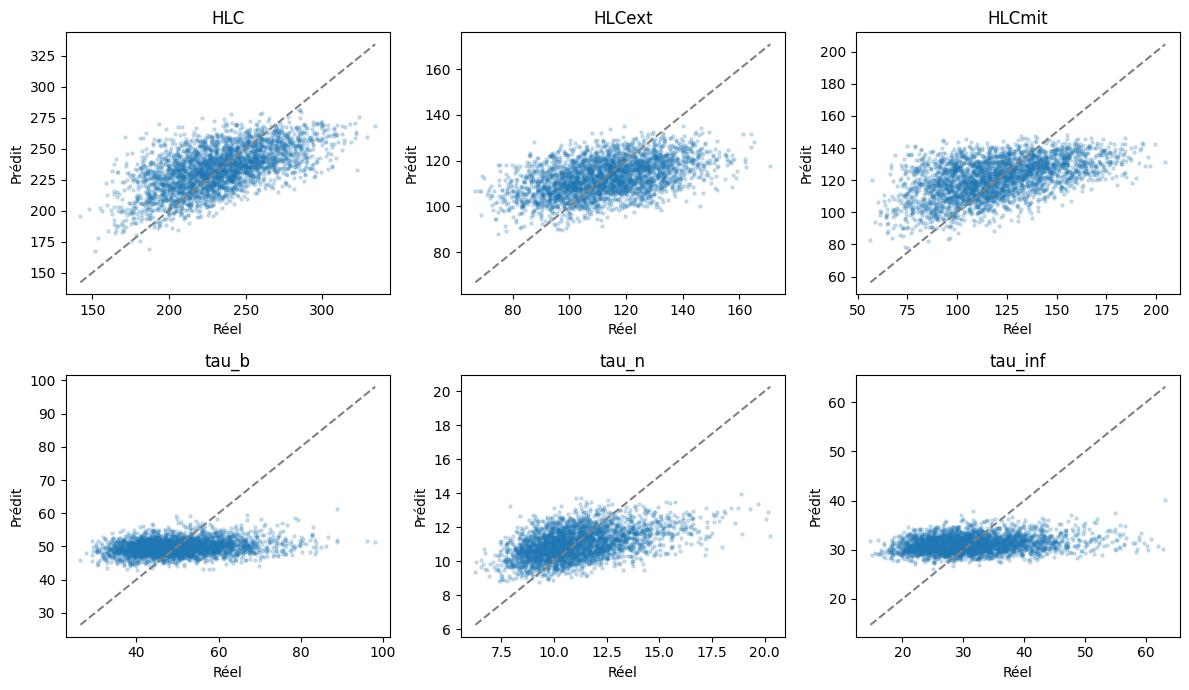

,partition,target,region,n,RMSE,bias
0,test,tau_b,5 % faibles,4447,15.688900,15.455000
1,test,tau_b,5 % élevés,4446,24.794300,-23.974899
2,test,tau_inf,5 % faibles,4475,11.319500,11.168200
3,test,tau_inf,5 % élevés,4399,19.049801,-18.360600
4,reserve_u,tau_b,5 % faibles,5055,15.860600,15.620700
5,reserve_u,tau_b,5 % élevés,5095,24.866600,-24.026600
6,reserve_u,tau_inf,5 % faibles,4987,11.465700,11.316500
7,reserve_u,tau_inf,5 % élevés,5094,19.065701,-18.374701


In [15]:
plot_scatter(
    output_directory / "predictions" / "test.npz",
    output_directory / "figures",
    seed=config.seed,
)

extreme_metrics = extreme_diagnostics(experiment)
display(extreme_metrics.round(4))


## 11. Sauvegarde des résultats

Les modèles entraînés, les configurations, les historiques d'entraînement, les métriques d'évaluation, les prédictions et les figures sont enregistrés afin d'assurer la traçabilité et la reproductibilité des expériences.

L'ensemble des résultats est également regroupé dans une archive ZIP.

In [ ]:
results_dir = Path("/kaggle/working/results/cnn/run_001")

# Vérifier que l'évaluation est terminée
if not (results_dir / "metrics.csv").exists():
    raise FileNotFoundError("Évaluation non terminée : metrics.csv absent.")

# Créer l'archive avec les résultats complets
archive = shutil.make_archive(
    "/kaggle/working/cnn",
    "zip",
    root_dir=results_dir
)

file = Path(archive)

print("Fichier prêt :", file.exists())
print("Taille :", round(file.stat().st_size / 1024**2, 2), "Mo")
print("Nom :", file.name)



Fichier prêt : True
Taille : 11.59 Mo



## 12. Analyse et interprétation des résultats

Le réseau convolutif unidimensionnel (CNN 1D) exploite directement les séries temporelles de température et de sollicitation thermique. Contrairement au MLP, il apprend des représentations à partir des variations locales des signaux.

### Performances prédictives

| Paramètre | R² — Test | R² — Réserve U |
|---|---:|---:|
| HLC | 0.366 | 0.380 |
| HLCext | 0.233 | 0.223 |
| HLCmit | 0.244 | 0.253 |
| τb | 0.051 | 0.047 |
| τn | 0.205 | 0.193 |
| τ∞ | 0.047 | 0.042 |

Les résultats montrent une amélioration par rapport au MLP sur l'ensemble des six indicateurs du test principal. Le gain est particulièrement visible pour HLCext, dont le R² passe de 0.144 à 0.233, ainsi que pour τn, qui passe de 0.169 à 0.205.

Ces résultats suggèrent que les motifs temporels locaux contiennent des informations utiles à l'identification thermique, au-delà des caractéristiques statistiques prédéfinies.

Toutefois, les performances sur τb et τ∞ restent faibles. Leurs prédictions demeurent concentrées autour des valeurs moyennes, ce qui indique que l'extraction de motifs locaux ne suffit pas à restituer l'ensemble des variations dynamiques.

La réserve U présente des performances globalement proches du test principal, bien que légèrement inférieures pour plusieurs indicateurs.

### Conclusion

L'exploitation directe des séries temporelles améliore les performances par rapport au MLP. Néanmoins, le CNN 1D reste limité dans sa capacité à représenter les dépendances temporelles plus longues. Cette observation motive l'introduction d'un module récurrent GRU après l'encodage convolutif.
